<a href="https://colab.research.google.com/github/WijayaPrat/CNN-Facial-Emotion-Recognition-using-CNN/blob/master/FER2013_with_4_CNN_Architecture_for_Paper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1 — Setup & Check GPU

In [ ]:
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Subset, random_split
from torch.cuda.amp import autocast, GradScaler
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, time, copy, json, gc
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'Memory : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
print('Setup selesai.')

Device : cuda
GPU    : Tesla T4
Memory : 15.6 GB
Setup selesai.


## 2 — Mount Drive & Path Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

TRAIN_DIR  = '/content/drive/MyDrive/fer-2013/train'
TEST_DIR   = '/content/drive/MyDrive/fer-2013/test'
OUTPUT_DIR = '/content/drive/MyDrive/FER2013_Paper_Results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

for tag, d in [('train', TRAIN_DIR), ('test', TEST_DIR)]:
    total = 0
    print(f'Isi folder {tag}:')
    for folder in sorted(os.listdir(d)):
        c = len(os.listdir(os.path.join(d, folder)))
        total += c
        print(f'  {folder:<12}: {c:,}')
    print(f'  Total: {total:,}\n')

Mounted at /content/drive
Isi folder train:
  angry       : 3,995
  disgust     : 436
  fear        : 4,097
  happy       : 7,215
  neutral     : 4,965
  sad         : 4,830
  surprise    : 3,171
  Total: 28,709

Isi folder test:
  angry       : 958
  disgust     : 111
  fear        : 1,024
  happy       : 1,774
  neutral     : 1,233
  sad         : 1,247
  surprise    : 831
  Total: 7,178



## 3 — CONFIG

In [ ]:
CONFIG = {
    'img_size'      : 224,
    'batch_size'    : 32,
    'num_classes'   : 7,
    'max_epochs'    : 50,          # ceiling; early stopping yang menentukan
    'early_stop_patience': 7,
    'optimizer'     : 'Adam',
    'learning_rate' : 1e-4,
    'weight_decay'  : 1e-4,        # regularisasi L2
    'lr_scheduler'  : 'ReduceLROnPlateau(mode=min, factor=0.5, patience=3)',
    'loss'          : 'Weighted CrossEntropy (inverse class frequency)',
    'mixed_precision': True,       # AMP — lebih cepat & hemat VRAM di T4
    'train_val_split': '80/20 (seed=42)',
    'test_set'      : 'FER-2013 official PrivateTest folder',
    'transfer_learning': 'ImageNet pretrained, partial fine-tuning',
    'framework'     : f'PyTorch {torch.__version__}',
}

AUGMENTATION = [
    'Resize(224x224)',
    'Grayscale->3ch (replicate)',
    'RandomHorizontalFlip(p=0.5)',
    'RandomRotation(15 deg)',
    'RandomAffine(translate=0.1)',
    'ColorJitter(brightness=0.2, contrast=0.2)',
    'Normalize(ImageNet mean/std)',
]

EMOTIONS = ['angry','disgust','fear','happy','neutral','sad','surprise']

print('='*60); print('EXPERIMENTAL CONFIGURATION (untuk paper)'); print('='*60)
for k, v in CONFIG.items():
    print(f'  {k:<20}: {v}')
print('\n  Augmentation pipeline (train only):')
for a in AUGMENTATION:
    print(f'    - {a}')
print('='*60)

EXPERIMENTAL CONFIGURATION (untuk paper)
  img_size            : 224
  batch_size          : 32
  num_classes         : 7
  max_epochs          : 50
  early_stop_patience : 7
  optimizer           : Adam
  learning_rate       : 0.0001
  weight_decay        : 0.0001
  lr_scheduler        : ReduceLROnPlateau(mode=min, factor=0.5, patience=3)
  loss                : Weighted CrossEntropy (inverse class frequency)
  mixed_precision     : True
  train_val_split     : 80/20 (seed=42)
  test_set            : FER-2013 official PrivateTest folder
  transfer_learning   : ImageNet pretrained, partial fine-tuning
  framework           : PyTorch 2.11.0+cu128

  Augmentation pipeline (train only):
    - Resize(224x224)
    - Grayscale->3ch (replicate)
    - RandomHorizontalFlip(p=0.5)
    - RandomRotation(15 deg)
    - RandomAffine(translate=0.1)
    - ColorJitter(brightness=0.2, contrast=0.2)
    - Normalize(ImageNet mean/std)


## 4 — Data Loaders (bug transform validasi sudah benar)

In [ ]:
IMG_SIZE, BATCH_SIZE = CONFIG['img_size'], CONFIG['batch_size']

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])

full_train   = ImageFolder(TRAIN_DIR, transform=train_transform)
test_dataset = ImageFolder(TEST_DIR,  transform=eval_transform)

# konfirmasi urutan kelas cocok dengan EMOTIONS
assert full_train.classes == EMOTIONS, f'Urutan kelas beda: {full_train.classes}'

val_size   = int(0.2 * len(full_train))
train_size = len(full_train) - val_size
g = torch.Generator().manual_seed(42)
tr_idx, va_idx = random_split(range(len(full_train)), [train_size, val_size], generator=g)

train_dataset = Subset(full_train, tr_idx.indices)
val_full = copy.deepcopy(full_train); val_full.transform = eval_transform
val_dataset = Subset(val_full, va_idx.indices)

# class weights (atasi imbalance 'disgust')
labels_all   = np.array(full_train.targets)
class_counts = np.bincount(labels_all)
class_weights = torch.FloatTensor(1.0 / class_counts)
class_weights = (class_weights / class_weights.sum() * 7).to(device)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train : {len(train_dataset):,}')
print(f'Val   : {len(val_dataset):,}')
print(f'Test  : {len(test_dataset):,}')
print(f'Kelas : {full_train.classes}')
print(f'Class weights: {class_weights.cpu().numpy().round(3)}')

Train : 22,968
Val   : 5,741
Test  : 7,178
Kelas : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Class weights: [0.48  4.398 0.468 0.266 0.386 0.397 0.605]


## 5 — Definisi Model (SATU definisi per model — bug ganda sudah dihapus)

Strategi fine-tuning dibuat **setara** untuk keempat model: backbone dibekukan, hanya blok terakhir + classifier yang dilatih, plus dropout. Ini menjaga perbandingan tetap adil (penting untuk menjawab reviewer).

In [ ]:
NUM_CLASSES = CONFIG['num_classes']

def build_vgg16():
    m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    for p in m.features.parameters(): p.requires_grad = False
    m.classifier[6] = nn.Linear(4096, NUM_CLASSES)
    return m

def build_resnet50():
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    for name, p in m.named_parameters():
        if 'layer4' not in name and 'fc' not in name: p.requires_grad = False
    m.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(m.fc.in_features, NUM_CLASSES))
    return m

def build_mobilenetv2():

    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    for p in m.features.parameters(): p.requires_grad = False
    for p in m.features[17].parameters(): p.requires_grad = True
    for p in m.features[18].parameters(): p.requires_grad = True
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.last_channel, NUM_CLASSES))
    return m

def build_efficientnet_b0():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    for p in m.features.parameters(): p.requires_grad = False
    for p in m.features[7].parameters(): p.requires_grad = True
    for p in m.features[8].parameters(): p.requires_grad = True
    inf = m.classifier[1].in_features
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(inf, NUM_CLASSES))
    return m


MODEL_BUILDERS = {
    'VGG16'          : build_vgg16,
    'ResNet50'       : build_resnet50,
    'MobileNetV2'    : build_mobilenetv2,
    'EfficientNet-B0': build_efficientnet_b0,
}

def count_parameters(m):
    total = sum(p.numel() for p in m.parameters())
    train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, train

print('Table II: Model Architecture Summary')
print('='*70)
print(f'{"Model":<18}{"Total Params":>15}{"Trainable":>15}{"Size(MB)":>12}')
print('-'*70)
for name, fn in MODEL_BUILDERS.items():
    t, tr = count_parameters(fn())
    print(f'{name:<18}{t:>15,}{tr:>15,}{t*4/1024**2:>11.1f}M')
print('='*70)

Table II: Model Architecture Summary
Model                Total Params      Trainable    Size(MB)
----------------------------------------------------------------------
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 142MB/s]


VGG16                 134,289,223    119,574,535      512.3M
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 37.0MB/s]


ResNet50               23,522,375     14,979,079       89.7M
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 132MB/s]


MobileNetV2             2,232,839        895,047        8.5M
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 147MB/s]


EfficientNet-B0         4,016,515      1,138,359       15.3M


## 6 — Fungsi Training (AMP + early stopping + auto-save bobot/history/prediksi)

In [ ]:
def train_model(name, num_epochs=None, lr=None, patience=None):
    num_epochs = num_epochs or CONFIG['max_epochs']
    lr         = lr        or CONFIG['learning_rate']
    patience   = patience  or CONFIG['early_stop_patience']

    model = MODEL_BUILDERS[name]().to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                           lr=lr, weight_decay=CONFIG['weight_decay'])
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
    scaler = GradScaler()

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc, best_weights, no_improve = 0.0, None, 0
    t0 = time.time()
    slug = name.lower().replace('-', '').replace(' ', '')

    print(f'\n{"="*58}\n  Training {name}  |  max_epochs={num_epochs}  patience={patience}\n{"="*58}', flush=True)
    for epoch in range(num_epochs):
        te = time.time()
        model.train(); tl = tc = tt = 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            with autocast():
                out  = model(imgs)
                loss = criterion(out, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            tl += loss.item()*imgs.size(0); tc += out.argmax(1).eq(labels).sum().item(); tt += labels.size(0)
        tl /= tt; ta = 100*tc/tt

        model.eval(); vl = vc = vt = 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                with autocast():
                    out  = model(imgs)
                    loss = criterion(out, labels)
                vl += loss.item()*imgs.size(0); vc += out.argmax(1).eq(labels).sum().item(); vt += labels.size(0)
        vl /= vt; va = 100*vc/vt
        scheduler.step(vl)

        for k, v in zip(history, [tl, vl, ta, va]): history[k].append(v)

        mark = ''
        if va > best_val_acc:
            best_val_acc, best_weights, no_improve, mark = va, copy.deepcopy(model.state_dict()), 0, ' * BEST'
            torch.save(best_weights, f'{OUTPUT_DIR}/best_{slug}.pth')
        else:
            no_improve += 1
        print(f'Epoch [{epoch+1:>2}/{num_epochs}] '
              f'| Train {tl:.3f}/{ta:.2f}%  | Val {vl:.3f}/{va:.2f}% '
              f'| {time.time()-te:.0f}s | tot {(time.time()-t0)/60:.1f}m{mark}', flush=True)
        if no_improve >= patience:
            print(f'\nEarly stopping di epoch {epoch+1}', flush=True); break

    model.load_state_dict(best_weights)

    with open(f'{OUTPUT_DIR}/history_{slug}.json', 'w') as f: json.dump(history, f)

    model.eval(); preds, labs = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            with autocast():
                out = model(imgs.to(device))
            preds.extend(out.argmax(1).cpu().numpy()); labs.extend(labels.numpy())
    np.savez(f'{OUTPUT_DIR}/preds_{slug}.npz', preds=np.array(preds), labels=np.array(labs))
    print(f'{name} selesai | Best Val Acc: {best_val_acc:.2f}% | tersimpan ke Drive', flush=True)
    del model; torch.cuda.empty_cache(); gc.collect()
    return history, best_val_acc

print('Fungsi training siap.')

Fungsi training siap.


## 7 — TRAINING keempat model (jumlah epoch SAMA = perbandingan adil)

Jalankan satu per satu. Kalau Colab terputus, cukup jalankan ulang model yang belum selesai — bobot & prediksi model sebelumnya sudah aman di Drive.

In [ ]:
hist_vgg,   acc_vgg   = train_model('VGG16')


  Training VGG16  |  max_epochs=50  patience=7


/tmp/ipykernel_870/3702422988.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_870/3702422988.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_870/3702422988.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [ 1/50] | Train 1.720/35.16%  | Val 1.568/45.48% | 2975s | tot 49.6m * BEST
Epoch [ 2/50] | Train 1.547/41.99%  | Val 1.419/48.25% | 193s | tot 52.8m * BEST
Epoch [ 3/50] | Train 1.479/44.44%  | Val 1.366/51.98% | 208s | tot 56.3m * BEST
Epoch [ 4/50] | Train 1.430/46.60%  | Val 1.429/50.27% | 205s | tot 59.7m
Epoch [ 5/50] | Train 1.400/47.67%  | Val 1.404/51.52% | 193s | tot 62.9m
Epoch [ 6/50] | Train 1.377/48.89%  | Val 1.470/52.69% | 196s | tot 66.2m * BEST
Epoch [ 7/50] | Train 1.353/48.93%  | Val 1.410/54.57% | 213s | tot 69.7m * BEST
Epoch [ 8/50] | Train 1.282/51.59%  | Val 1.350/53.28% | 211s | tot 73.2m
Epoch [ 9/50] | Train 1.255/52.58%  | Val 1.324/55.06% | 197s | tot 76.5m * BEST
Epoch [10/50] | Train 1.249/52.72%  | Val 1.375/55.91% | 207s | tot 80.0m * BEST
Epoch [11/50] | Train 1.220/53.34%  | Val 1.370/56.04% | 204s | tot 83.4m * BEST
Epoch [12/50] | Train 1.200/54.27%  | Val 1.425/56.23% | 206s | tot 86.8m * BEST
Epoch [13/50] | Train 1.188/54.78%  | Val 1.331/

/tmp/ipykernel_870/3702422988.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


VGG16 selesai | Best Val Acc: 57.62% | tersimpan ke Drive


In [ ]:
hist_res,   acc_res   = train_model('ResNet50')


  Training ResNet50  |  max_epochs=50  patience=7


/tmp/ipykernel_870/3702422988.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_870/3702422988.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_870/3702422988.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [ 1/50] | Train 1.472/45.30%  | Val 1.316/54.01% | 178s | tot 3.0m * BEST
Epoch [ 2/50] | Train 1.245/53.98%  | Val 1.218/57.46% | 178s | tot 5.9m * BEST
Epoch [ 3/50] | Train 1.156/56.63%  | Val 1.303/56.16% | 180s | tot 8.9m
Epoch [ 4/50] | Train 1.078/59.24%  | Val 1.159/57.90% | 177s | tot 11.9m * BEST
Epoch [ 5/50] | Train 1.030/60.44%  | Val 1.219/58.98% | 180s | tot 14.9m * BEST
Epoch [ 6/50] | Train 0.992/62.41%  | Val 1.144/59.83% | 181s | tot 17.9m * BEST
Epoch [ 7/50] | Train 0.952/63.11%  | Val 1.133/61.00% | 178s | tot 20.9m * BEST
Epoch [ 8/50] | Train 0.921/64.45%  | Val 1.184/60.44% | 178s | tot 23.8m
Epoch [ 9/50] | Train 0.897/65.58%  | Val 1.107/63.04% | 177s | tot 26.8m * BEST
Epoch [10/50] | Train 0.862/66.37%  | Val 1.174/61.10% | 178s | tot 29.8m
Epoch [11/50] | Train 0.846/67.05%  | Val 1.210/63.06% | 180s | tot 32.8m * BEST
Epoch [12/50] | Train 0.815/68.38%  | Val 1.163/62.74% | 180s | tot 35.8m
Epoch [13/50] | Train 0.801/68.83%  | Val 1.168/62.32% | 17

/tmp/ipykernel_870/3702422988.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


ResNet50 selesai | Best Val Acc: 65.58% | tersimpan ke Drive


In [ ]:
hist_mob,   acc_mob   = train_model('MobileNetV2')


  Training MobileNetV2  |  max_epochs=50  patience=7


/tmp/ipykernel_870/3702422988.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_870/3702422988.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_870/3702422988.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [ 1/50] | Train 1.678/35.94%  | Val 1.576/42.01% | 179s | tot 3.0m * BEST
Epoch [ 2/50] | Train 1.523/42.64%  | Val 1.535/42.26% | 170s | tot 5.8m * BEST
Epoch [ 3/50] | Train 1.458/45.08%  | Val 1.511/42.47% | 171s | tot 8.7m * BEST
Epoch [ 4/50] | Train 1.424/46.85%  | Val 1.474/46.70% | 170s | tot 11.5m * BEST
Epoch [ 5/50] | Train 1.387/47.74%  | Val 1.450/46.58% | 179s | tot 14.5m
Epoch [ 6/50] | Train 1.367/48.53%  | Val 1.510/46.28% | 172s | tot 17.4m
Epoch [ 7/50] | Train 1.358/49.18%  | Val 1.438/47.22% | 181s | tot 20.4m * BEST
Epoch [ 8/50] | Train 1.326/49.90%  | Val 1.421/47.47% | 175s | tot 23.3m * BEST
Epoch [ 9/50] | Train 1.306/50.44%  | Val 1.403/47.15% | 172s | tot 26.2m
Epoch [10/50] | Train 1.297/51.19%  | Val 1.420/51.23% | 172s | tot 29.0m * BEST
Epoch [11/50] | Train 1.290/51.04%  | Val 1.381/50.81% | 172s | tot 31.9m
Epoch [12/50] | Train 1.271/51.83%  | Val 1.397/50.15% | 169s | tot 34.7m
Epoch [13/50] | Train 1.259/51.85%  | Val 1.369/50.04% | 169s | to

/tmp/ipykernel_870/3702422988.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


MobileNetV2 selesai | Best Val Acc: 52.03% | tersimpan ke Drive


In [ ]:
hist_eff,   acc_eff   = train_model('EfficientNet-B0')


  Training EfficientNet-B0  |  max_epochs=50  patience=7


/tmp/ipykernel_870/3702422988.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_870/3702422988.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_870/3702422988.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [ 1/50] | Train 1.729/34.94%  | Val 1.576/42.97% | 182s | tot 3.0m * BEST
Epoch [ 2/50] | Train 1.541/42.74%  | Val 1.470/44.31% | 183s | tot 6.1m * BEST
Epoch [ 3/50] | Train 1.446/46.53%  | Val 1.374/48.56% | 180s | tot 9.1m * BEST
Epoch [ 4/50] | Train 1.380/48.33%  | Val 1.342/50.50% | 179s | tot 12.1m * BEST
Epoch [ 5/50] | Train 1.339/50.11%  | Val 1.299/51.56% | 179s | tot 15.1m * BEST
Epoch [ 6/50] | Train 1.317/51.01%  | Val 1.291/52.67% | 178s | tot 18.0m * BEST
Epoch [ 7/50] | Train 1.281/51.75%  | Val 1.271/53.98% | 178s | tot 21.0m * BEST
Epoch [ 8/50] | Train 1.255/53.11%  | Val 1.242/54.24% | 177s | tot 23.9m * BEST
Epoch [ 9/50] | Train 1.240/53.15%  | Val 1.250/54.89% | 176s | tot 26.9m * BEST
Epoch [10/50] | Train 1.204/54.21%  | Val 1.230/54.19% | 175s | tot 29.8m
Epoch [11/50] | Train 1.202/54.35%  | Val 1.222/53.70% | 176s | tot 32.7m
Epoch [12/50] | Train 1.181/55.46%  | Val 1.210/54.97% | 177s | tot 35.7m * BEST
Epoch [13/50] | Train 1.167/55.57%  | Val 1.2

/tmp/ipykernel_870/3702422988.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


EfficientNet-B0 selesai | Best Val Acc: 58.94% | tersimpan ke Drive


## 8 —  Evaluation Function & Plot

In [ ]:
def load_preds(name):
    slug = name.lower().replace('-', '').replace(' ', '')
    d = np.load(f'{OUTPUT_DIR}/preds_{slug}.npz')
    return d['preds'], d['labels']

def load_history(name):
    slug = name.lower().replace('-', '').replace(' ', '')
    with open(f'{OUTPUT_DIR}/history_{slug}.json') as f: return json.load(f)

def evaluate(name):
    preds, labs = load_preds(name)
    acc  = accuracy_score(labs, preds)*100
    prec = precision_score(labs, preds, average='weighted', zero_division=0)*100
    rec  = recall_score(labs, preds, average='weighted', zero_division=0)*100
    f1   = f1_score(labs, preds, average='weighted', zero_division=0)*100
    f1pc = f1_score(labs, preds, average=None, zero_division=0)*100
    print(f'{name:<18} Acc {acc:.2f}%  Prec {prec:.2f}%  Rec {rec:.2f}%  F1 {f1:.2f}%')
    return {'name': name, 'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1,
            'f1pc': f1pc, 'preds': preds, 'labels': labs}

def plot_curves(names):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    colors = ['#E24B4A', '#185FA5', '#1D9E75', '#B36AE2', '#E2A33B']
    for i, nm in enumerate(names):
        h = load_history(nm); ep = range(1, len(h['train_loss'])+1); c = colors[i]
        ax[0].plot(ep, h['train_loss'], '--', color=c, alpha=.6)
        ax[0].plot(ep, h['val_loss'],  '-',  color=c, lw=1.8, label=nm)
        ax[1].plot(ep, h['train_acc'], '--', color=c, alpha=.6)
        ax[1].plot(ep, h['val_acc'],   '-',  color=c, lw=1.8, label=nm)
    ax[0].set_title('Loss (solid=val, dashed=train)', fontweight='bold')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].set_title('Accuracy (solid=val, dashed=train)', fontweight='bold')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/fig_training_curves.png', dpi=300, bbox_inches='tight'); plt.show()

def plot_confusions(results):
    n = len(results); ncols = 2 if n > 1 else 1; nrows = int(np.ceil(n/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 5.5*nrows))
    axes = np.array(axes).reshape(-1)
    for ax, r in zip(axes, results):
        cm = confusion_matrix(r['labels'], r['preds']).astype(float)
        cm = cm / cm.sum(1, keepdims=True) * 100
        sns.heatmap(cm, annot=True, fmt='.1f', cmap='Blues', xticklabels=EMOTIONS,
                    yticklabels=EMOTIONS, ax=ax, cbar=True, linewidths=.3)
        ax.set_title(f'{r["name"]}  (Acc {r["acc"]:.2f}%)', fontweight='bold')
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        ax.tick_params(axis='x', rotation=30); ax.tick_params(axis='y', rotation=0)
    for ax in axes[n:]: ax.axis('off')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/fig_confusion.png', dpi=300, bbox_inches='tight'); plt.show()

print('Fungsi evaluasi siap.')

Fungsi evaluasi siap.


## 9 — Evaluasi semua model + Tabel III/IV + Figures

Overall Performance (FER-2013 Test Set)
VGG16              Acc 56.90%  Prec 56.86%  Rec 56.90%  F1 56.55%
ResNet50           Acc 65.95%  Prec 66.42%  Rec 65.95%  F1 65.94%
MobileNetV2        Acc 52.27%  Prec 53.71%  Rec 52.27%  F1 51.59%
EfficientNet-B0    Acc 58.36%  Prec 58.88%  Rec 58.36%  F1 58.29%

Per-Class F1-Score
Emotion           VGG16     ResNet50  MobileNetV2 EfficientNet
--------------------------------------------------------------
angry             48.1%        60.0%        41.1%        48.2%
disgust           31.4%        66.7%        29.7%        41.3%
fear              40.5%        45.2%        24.9%        38.8%
happy             76.8%        86.6%        73.3%        81.1%
neutral           54.0%        63.3%        50.1%        53.6%
sad               43.7%        54.6%        43.9%        46.2%
surprise          69.4%        75.2%        66.9%        72.7%


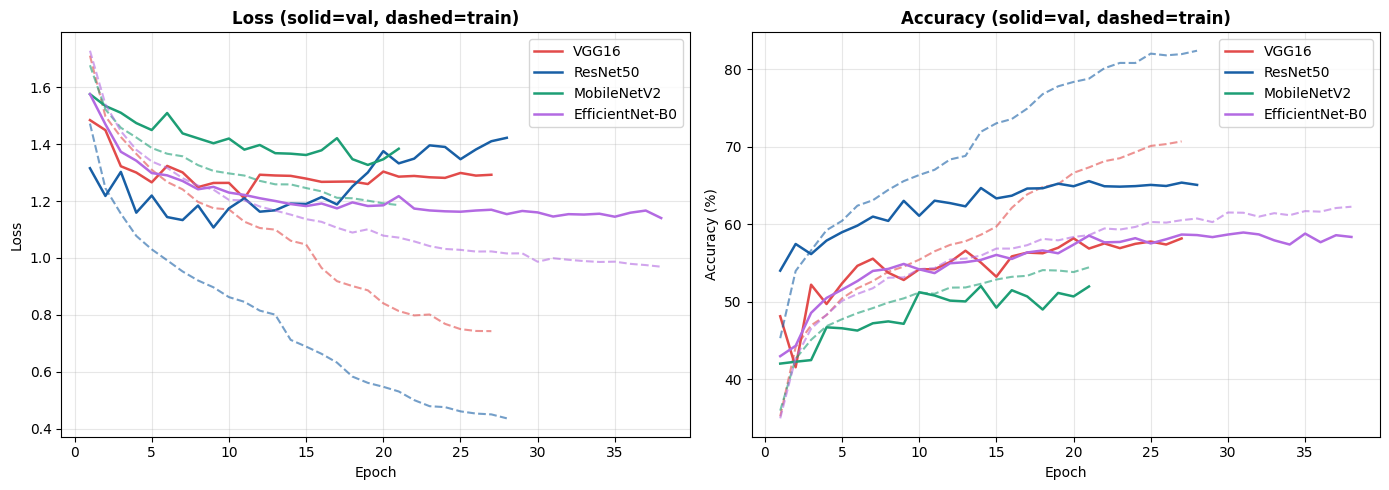

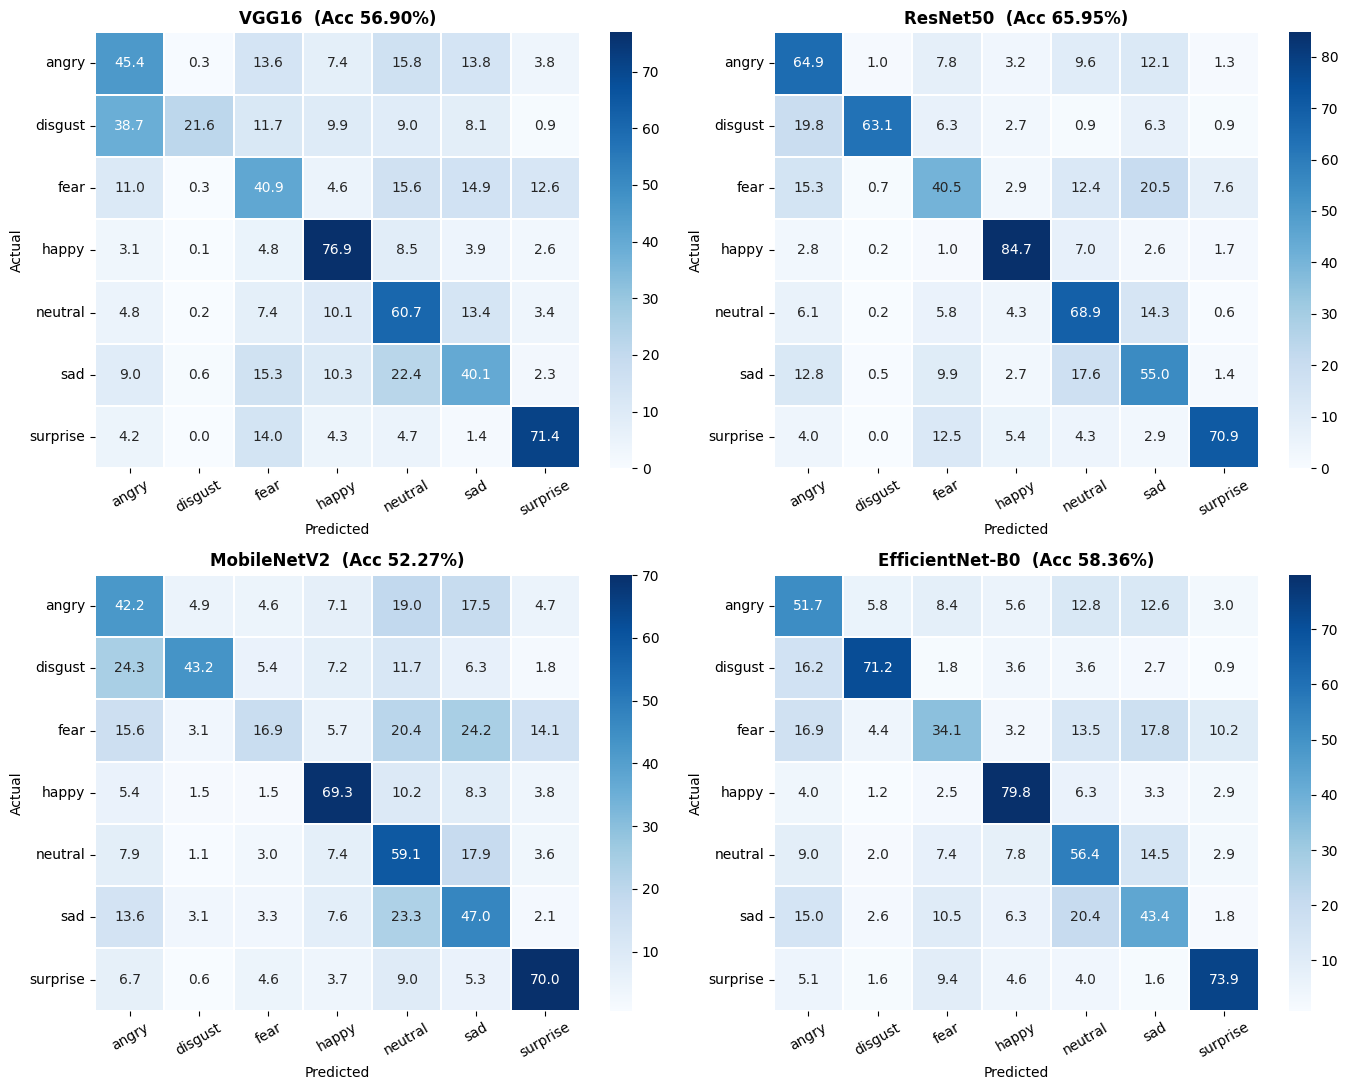


Figures tersimpan ke Drive.


In [ ]:
NAMES = ['VGG16', 'ResNet50', 'MobileNetV2', 'EfficientNet-B0']

print('='*60); print('Overall Performance (FER-2013 Test Set)'); print('='*60)
results = [evaluate(n) for n in NAMES]

# Table IV: per-class F1
print('\n' + '='*60); print('Per-Class F1-Score'); print('='*60)
hdr = f'{"Emotion":<10}' + ''.join(f'{r["name"][:12]:>13}' for r in results); print(hdr); print('-'*len(hdr))
for i, emo in enumerate(EMOTIONS):
    print(f'{emo:<10}' + ''.join(f'{r["f1pc"][i]:>12.1f}%' for r in results))
print('='*60)

plot_curves(NAMES)
plot_confusions(results)
print('\nFigures tersimpan ke Drive.')

## 10 — Validasi Statistik



In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

def bootstrap_ci(preds, labels, n_boot=2000, alpha=0.05):
    preds, labels = np.array(preds), np.array(labels)
    correct = (preds == labels).astype(int); n = len(correct)
    accs = [correct[np.random.randint(0, n, n)].mean()*100 for _ in range(n_boot)]
    lo, hi = np.percentile(accs, [100*alpha/2, 100*(1-alpha/2)])
    return correct.mean()*100, lo, hi

print('='*60); print('Bootstrap 95% Confidence Interval (Test Accuracy)'); print('='*60)
for r in results:
    acc, lo, hi = bootstrap_ci(r['preds'], r['labels'])
    print(f'  {r["name"]:<18}: {acc:.2f}%  (95% CI: {lo:.2f} - {hi:.2f})')

print('\n' + '='*60); print("McNemar's Test — ResNet50 vs model lain"); print('='*60)
ref = next(r for r in results if r['name'] == 'ResNet50')
ref_correct = (np.array(ref['preds']) == np.array(ref['labels']))
for r in results:
    if r['name'] == 'ResNet50': continue
    oth = (np.array(r['preds']) == np.array(r['labels']))
    n01 = int(((~ref_correct) & (oth)).sum())   # ResNet salah, lain benar
    n10 = int(((ref_correct) & (~oth)).sum())   # ResNet benar, lain salah
    res = mcnemar([[0, n01], [n10, 0]], exact=False, correction=True)
    sig = 'signifikan (p<0.05)' if res.pvalue < 0.05 else 'tidak signifikan'
    print(f'  ResNet50 vs {r["name"]:<16}: chi2={res.statistic:.2f}, p={res.pvalue:.4g}  -> {sig}')
print('='*60)

Bootstrap 95% Confidence Interval (Test Accuracy)
  VGG16             : 56.90%  (95% CI: 55.80 - 58.09)
  ResNet50          : 65.95%  (95% CI: 64.82 - 66.98)
  MobileNetV2       : 52.27%  (95% CI: 51.17 - 53.44)
  EfficientNet-B0   : 58.36%  (95% CI: 57.23 - 59.53)

McNemar's Test — ResNet50 vs model lain
  ResNet50 vs VGG16           : chi2=210.39, p=1.129e-47  -> signifikan (p<0.05)
  ResNet50 vs MobileNetV2     : chi2=441.86, p=4.272e-98  -> signifikan (p<0.05)
  ResNet50 vs EfficientNet-B0 : chi2=172.16, p=2.502e-39  -> signifikan (p<0.05)


## 11 — Tabel Perbandingan SOTA

In [ ]:
# GANTI baris di bawah dengan hasil dari paper asli + sitasi Anda:
sota_rows = [
    # (Method, Year, Accuracy%, Citation_key)
    ('[Improved VGG16]', '2024', '68.85', '[24]'),
    ('[MobileNetV2 (resource-efficient)]', '2025', '73.82', '[25]'),
    ('[InsideOut (EfficientNetV2-S)]', '2025', '62.80', '[26]'),
]
best = max(results, key=lambda r: r['acc'])
print('='*66); print('Table: Comparison with State-of-the-Art on FER-2013'); print('='*66)
print(f'{"Method":<28}{"Year":>6}{"Accuracy":>12}{"Ref":>10}'); print('-'*66)
for m, y, a, ref in sota_rows:
    print(f'{m:<28}{y:>6}{a:>11}%{ref:>10}')
print(f'{"Ours ("+best["name"]+")":<28}{"2026":>6}{best["acc"]:>11.2f}%{"-":>10}')
print('='*66)
print('\nCatatan: human accuracy FER-2013 ~65±5%. Jelaskan gap secara jujur di Discussion.')

Table: Comparison with State-of-the-Art on FER-2013
Method                        Year    Accuracy       Ref
------------------------------------------------------------------
[Improved VGG16]              2024      68.85%      [24]
[MobileNetV2 (resource-efficient)]  2025      73.82%      [25]
[InsideOut (EfficientNetV2-S)]  2025      62.80%      [26]
Ours (ResNet50)               2026      65.95%         -

Catatan: human accuracy FER-2013 ~65±5%. Jelaskan gap secara jujur di Discussion.


## 12 — Tabel Efisiensi (parameter, ukuran, latency)

In [ ]:
def latency_ms(model, n=100):
    model.eval(); dummy = torch.randn(1, 3, 224, 224).to(device)
    with torch.no_grad():
        for _ in range(10): _ = model(dummy)
    if device.type == 'cuda': torch.cuda.synchronize()
    t = time.time()
    with torch.no_grad():
        for _ in range(n): _ = model(dummy)
    if device.type == 'cuda': torch.cuda.synchronize()
    return (time.time()-t)/n*1000

print('='*74); print('Table V: Efficiency Comparison'); print('='*74)
print(f'{"Model":<18}{"Params(M)":>12}{"Size(MB)":>11}{"Latency(ms)":>14}{"Test Acc":>11}'); print('-'*74)
acc_map = {r['name']: r['acc'] for r in results}
for name in NAMES:
    slug = name.lower().replace('-', '').replace(' ', '')
    m = MODEL_BUILDERS[name]().to(device)
    m.load_state_dict(torch.load(f'{OUTPUT_DIR}/best_{slug}.pth'));
    tot, _ = count_parameters(m)
    print(f'{name:<18}{tot/1e6:>11.1f}M{tot*4/1024**2:>10.1f}MB{latency_ms(m):>13.2f}ms{acc_map[name]:>10.2f}%')
    del m; torch.cuda.empty_cache(); gc.collect()
print('='*74)

Table V: Efficiency Comparison
Model                Params(M)   Size(MB)   Latency(ms)   Test Acc
--------------------------------------------------------------------------
VGG16                   134.3M     512.3MB        10.18ms     56.90%
ResNet50                 23.5M      89.7MB         6.16ms     65.95%
MobileNetV2               2.2M       8.5MB         5.88ms     52.27%
EfficientNet-B0           4.0M      15.3MB        11.99ms     58.36%


## 13 — Simpan Ringkasan CSV

In [ ]:
summary = pd.DataFrame([{
    'Model': r['name'], 'Accuracy': round(r['acc'],2), 'Precision': round(r['prec'],2),
    'Recall': round(r['rec'],2), 'F1': round(r['f1'],2),
    **{f'F1_{EMOTIONS[i]}': round(r['f1pc'][i],2) for i in range(7)}
} for r in results])
summary.to_csv(f'{OUTPUT_DIR}/results_summary.csv', index=False)
print(summary.to_string(index=False))
print(f'\nSemua hasil, gambar, bobot, dan prediksi tersimpan di:\n  {OUTPUT_DIR}')